# two-panel radius–insolation count density
- left: HPIC×LIFEcat ⊗ Exo-MerCat crossmatch, right: entire Exo-MerCat; shared log color scale
- exports to `report/figures/radius_insolation_heatmap.pdf`

In [25]:
%load_ext autoreload
%autoreload 2

import os, sys, pathlib

ROOT = pathlib.Path.cwd()
while not (ROOT / 'crossmatching').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt

from report_plots import common, data, plots
from collections import Counter

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
cme, input_table, matched = data.emc_crossmatch()
merger = data.build_param_filler()

e_cm_emc = data.enrich(matched, cme, merger)
e_emc = data.enrich(cme.catalog_table, cme, merger)
data.compute_is_rocky_temperate(e_cm_emc)
data.compute_is_rocky_temperate(e_emc)
data.rocky_temperate_summary(e_cm_emc=e_cm_emc, e_emc=e_emc)


e_cm_emc: 7 Confirmed + 13 Uncertain rocky, temperate planets
e_emc: 17 Confirmed + 66 Uncertain rocky, temperate planets


saved /home/joshuadreier/Documents/CodingProjects/SemesterProjectEHG/report/figures/radius_insolation_heatmap.pdf


PosixPath('/home/joshuadreier/Documents/CodingProjects/SemesterProjectEHG/report/figures/radius_insolation_heatmap.pdf')

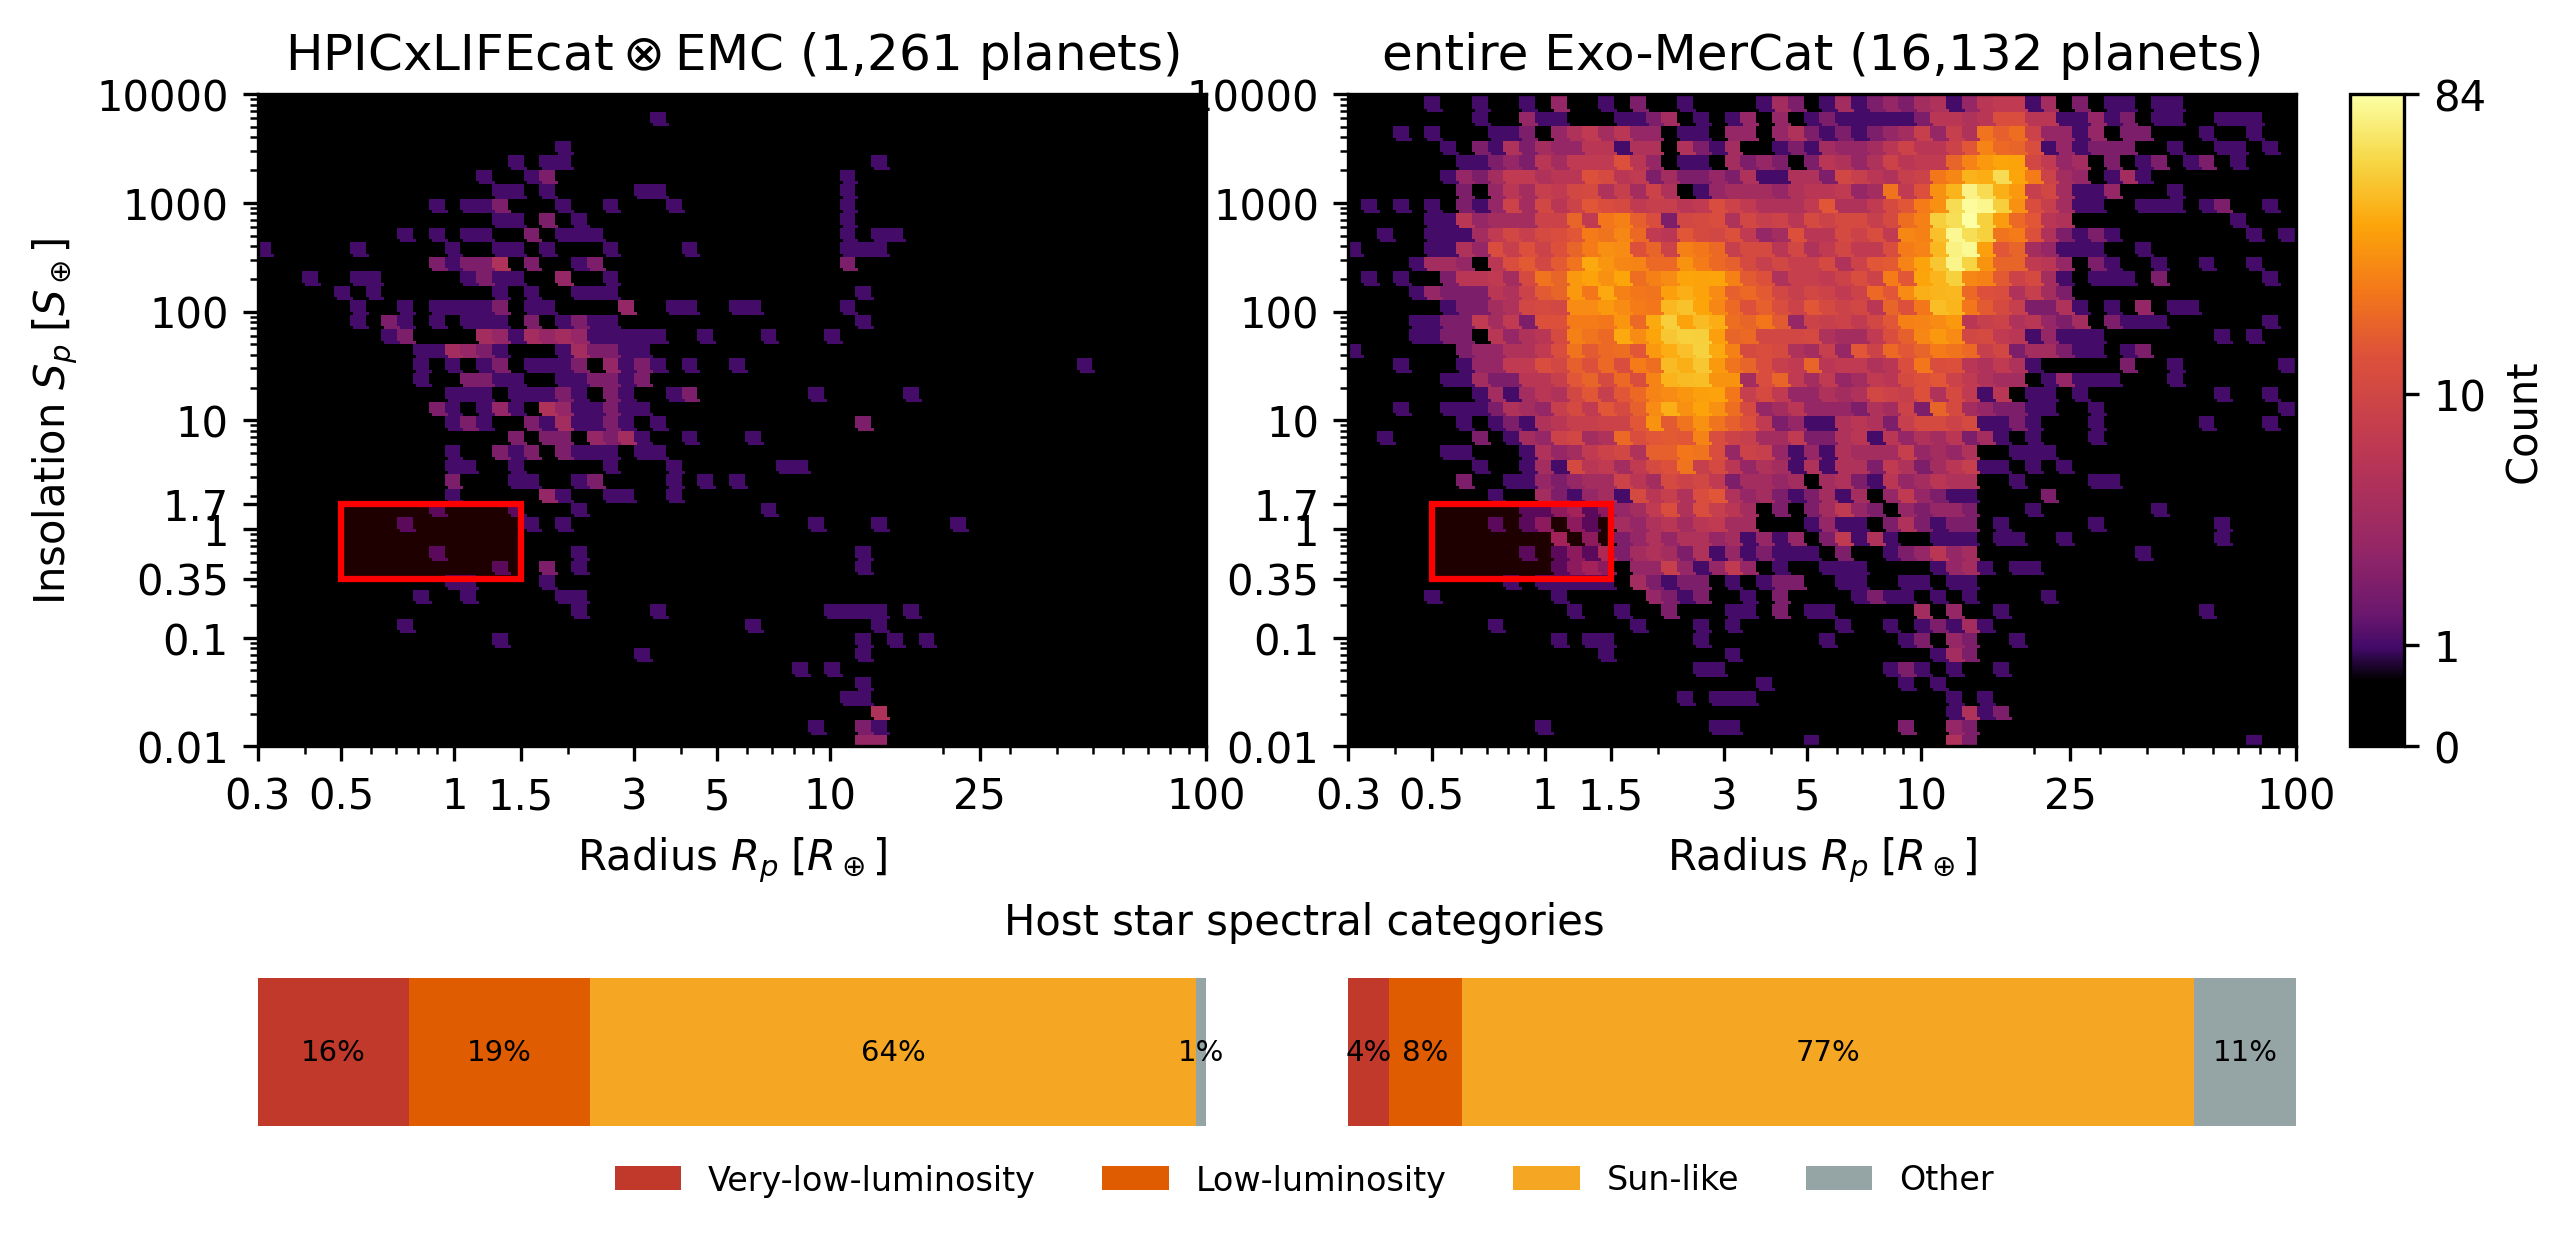

In [45]:
plots.double_hist_heatmap(
    e_cm_emc, e_emc,
    catalog1_name=rf"$\text{{HPICxLIFEcat}} \otimes \text{{EMC}}$ ({len(e_cm_emc):,} planets)",
    catalog2_name=f"entire Exo-MerCat ({len(e_emc):,} planets)",
    figsize=(9, 4.5),
    stellar_bars=True,
)
common.save_figure("radius_insolation_heatmap")

cm_specdc = Counter(e_cm_emc["spectral_category"])
ncm_specdc = Counter(e_emc["spectral_category"])
ncm_specdc 

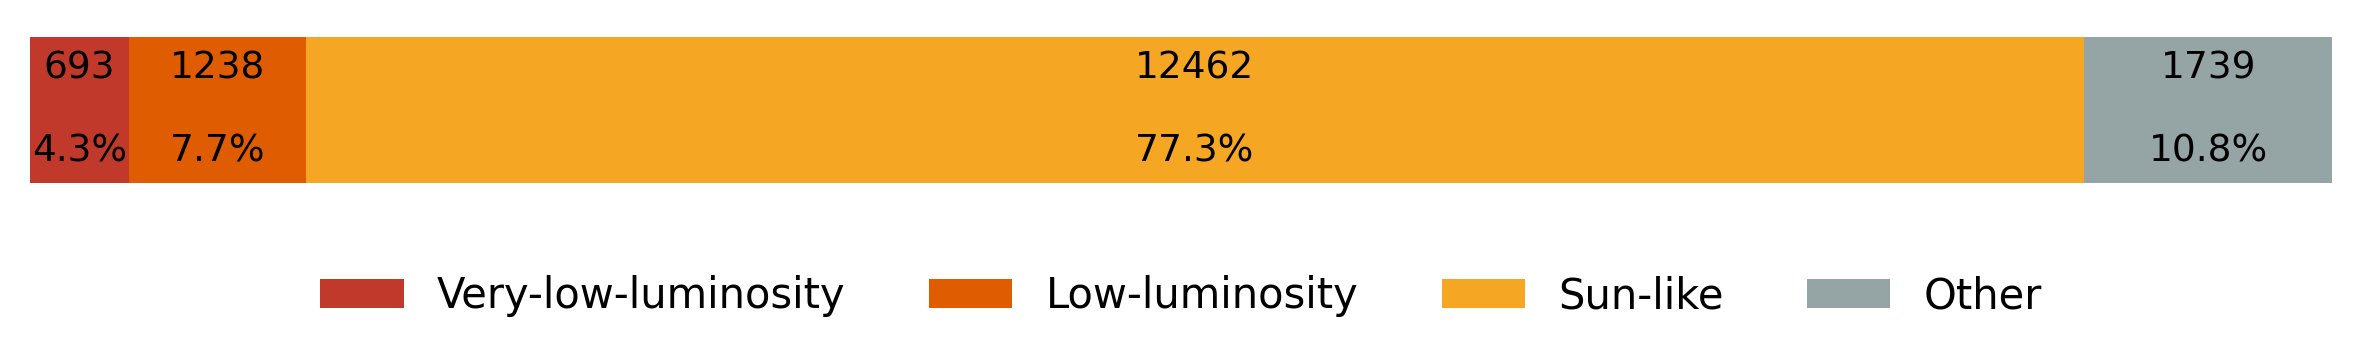

In [29]:
labels = common.CATEGORY_ORDER
values = [ncm_specdc[i] for i in labels]
total = sum(values)
colors = [common.CATEGORY_COLORS[i] for i in labels]
fig, ax = plt.subplots(figsize=(8, 1.5))

left = 0
for val, lab, col in zip(values, labels, colors):
    ax.barh(0, val, left=left, color=col, label=lab)
    ax.text(left + val / 2, 0, f'{val}\n\n{val/total*100:.1f}%', ha='center', va='center', fontsize=9)
    left += val

ax.set_xlim(0, sum(values))
ax.axis('off')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=len(values), frameon=False)
plt.tight_layout()
plt.show()